# MySteth 2.0 — RQ6: End-to-end integration

**RQ6 (methods document).** *Does integrating SQA, SSL representation, multi-task prediction, UQ, and XAI into one pipeline with two decision gates (quality gate, confidence gate) produce a system that is more clinically trustworthy end-to-end than any individual component improvement alone, measured not just by accuracy but by how well it knows when to defer to a clinician?*

Methodology, as written:
- pipeline order: raw audio → **SQA gate** (accept / reject / re-record) → SSL-pretrained shared encoder → multi-task heads (murmur + outcome) → UQ wrapper → **confidence gate** (predict vs flag for clinician) → XAI module on accepted high-confidence predictions;
- **ablation study:** remove each gate / module one at a time and measure system-level metrics each time;
- system-level metrics: weighted accuracy, F1, PhysioNet 2022 cost metric, ECE, % of cases correctly deferred to clinician, system-level trustworthiness evaluation;
- baseline: MySteth (no SQA, no UQ, no XAI) as the floor; closest competitors (CardioPHON, Xu et al.) as component-level ceilings.

### The five MySteth 2.0 components and their role here

| # | Component | In the full system | Removed in the ablation as |
|---|---|---|---|
| ① | SQA | **Quality gate:** out-of-fold `p_good` ≥ its fold threshold; a patient's decision uses passed recordings only; a patient with none is asked to **re-record** | all recordings used, nobody re-records |
| ② | SSL | encoder initialised from Domain-SSL (RQ2) | RQ3's joint model trained **from scratch** |
| ③ | Multi-task | one shared encoder, both heads (RQ3 system model) | RQ2's **separate** per-task Domain-SSL fine-tuned encoders |
| ④ | UQ | `ens_temp` (temperature-scaled 3-seed ensemble, RQ4) feeding the **confidence gate** | **single** seed-42 model, raw probability (the gate runs on that probability) |
| ⑤ | XAI | Grad-CAM (layer3) explains each accepted decision (RQ5) | no explanation; decisions are unchanged |

### Decisions fixed before writing this notebook

| Decision | Choice |
|---|---|
| Model outputs | Nothing is trained. Every probability is recomputed on CPU from the saved window logits of RQ3 (joint Domain-SSL, joint scratch) and RQ2 (separate encoders), with RQ3's code; checks require RQ3's and RQ4's probabilities, temperatures and thresholds to be reproduced |
| UQ wrapper | `ens_temp`, as in RQ1–RQ5 (fixed in RQ4; RQ4 also reports MC-Dropout + ensemble + temperature) |
| Level | Patient: murmur = maximum over the recordings used, outcome = mean (as RQ1–RQ5). Murmur metrics on Present/Absent patients, outcome on all |
| Decision thresholds | Unchanged from RQ2–RQ5 (each fold's validation patients) |
| SQA gate | The final SQA model's out-of-fold decision (`p_good` ≥ fold threshold), as RQ1 |
| Confidence gate | Each task keeps its own score (RQ3): **Chow risk** (RQ4's pre-set primary). A patient's combined risk is the **higher of the two task-risk percentiles**, and the gate defers exactly **20 %** of the patients that reach it (RQ4's main operating point) to a clinician, **for both tasks**. Patients are ranked without their labels, pooled across folds and re-ranked inside every bootstrap resample, as in RQ4 |
| Ablation rows | full system · − SQA gate · − SSL · − multi-task · − UQ · − confidence gate · − XAI · floor (no SQA, no UQ, no confidence gate, no XAI). Plus, as stated in the RQ1 report, − SQA gate with the confidence gate deferring the **same total number** of patients as the full system |
| Metrics (test patients) | **Patient workload:** share re-recorded, share deferred to a clinician, share fully automated (both tasks). **On automated decisions, per task:** weighted accuracy, F1 (macro), accuracy, AUC, ECE, sensitivity, specificity. **System cost** (outcome, PhysioNet 2022 `c_outcome`) over all patients, with patients not decided automatically counted as referred to expert screening. **Deferral (descriptive):** correctly deferred = share of the would-be errors that are deferred (RQ4's "share of errors removed"), errors left in automated decisions, AUROC of the task's Chow risk for its errors |
| Statistics | The same 1,000 patient-group bootstrap resamples as RQ1–RQ5; every row paired against the full system |
| Pre-set answer rule | Below (section 8), using the methods document's metrics |

### Changes after the first run (design corrections, made before looking at any new result)

The first run exposed three flaws in this notebook's own design; they are corrected here and stated in the report.

| Flaw in the first run | Correction |
|---|---|
| "Correctly deferred" (share of deferred patients that would have been wrong) rises when a system makes **more** errors, so it credited weaker systems | Removed from the answer rule; deferral is reported descriptively. The rule judges what remains after deferral: the automated decisions at the same workload |
| The gate cut-off set on 66–75 calibration patients per fold did not hold on test patients (outcome deferral 16–27 % across rows), so rows were not at the same workload | The gate defers exactly 20 % of the patients reaching it, ranked by risk without labels (RQ4's method) |
| One 20 % gate per task **compounded** at patient level: a clinician sees a patient flagged on either task (33 % of patients in the full system, only 45 % fully automated) | One patient-level gate over both tasks' risks: patient workload is exactly re-record + 20 % of the rest, in every row |

### Kaggle setup
- **CPU only.** Attach: the **RQ3 output** (`rq3_outputs`), the **RQ2b output** (`rq2_outputs`, for the separate-encoder units), the **RQ4 output** (`rq4_outputs`, reproduction check) and the final SQA output (`sqa_oof_predictions.csv`).
- Output: `/kaggle/working/rq6_outputs`.

In [1]:
import os, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY, PURPLE = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280", "#7D3C98"


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    rq3_dir: str = "/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs"
    rq2b_dir: str = "/kaggle/input/notebooks/tusharrbb/rq2-part-2-again/rq2_outputs"
    rq4_dir: str = "/kaggle/input/notebooks/tusharrbb/rq4-redone/rq4_outputs"
    sqa_oof_path: str = "/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv"
    output_dir: str = "/kaggle/working/rq6_outputs"

    # identical to RQ2–RQ5
    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    n_boot: int = 1000

    # RQ6
    budget: float = 0.20          # confidence gate: share of the patients reaching it that are deferred to a clinician (both tasks)

cfg = Config()
R3, R2, R4 = Path(cfg.rq3_dir), Path(cfg.rq2b_dir), Path(cfg.rq4_dir)
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
TASKS = ["murmur", "outcome"]
TK = {"murmur": "m", "outcome": "o"}
MODELS = ["joint_domain", "joint_scratch", "separate"]
RQ2_ARM = {"separate": "domain_finetune"}
METHODS = ["single", "ens_temp"]

for f in range(cfg.n_folds):
    for s in cfg.seeds:
        for m in ["joint_domain", "joint_scratch"]:
            assert (R3 / "units" / f"{m}_f{f}_s{s}.npz").exists(), f"RQ3 unit {m}_f{f}_s{s} not found: check rq3_dir"
        for t in TASKS:
            assert (R2 / "units" / f"domain_finetune_{t}_f{f}_s{s}.npz").exists(), f"RQ2 unit domain_finetune_{t}_f{f}_s{s} not found: check rq2b_dir"
for p_ in [R3 / "rq2_folds.csv", R3 / "rq2_windows.csv", R3 / "rq3_thresholds.csv", R3 / "rq3_temperatures.csv",
           R3 / "rq3_recording_predictions.csv", R3 / "rq3_patient_predictions.csv",
           R4 / "rq4_patient_scores.csv", Path(cfg.sqa_oof_path)]:
    assert p_.exists(), f"missing input: {p_}"
print(cfg)

Config(rq3_dir='/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs', rq2b_dir='/kaggle/input/notebooks/tusharrbb/rq2-part-2-again/rq2_outputs', rq4_dir='/kaggle/input/notebooks/tusharrbb/rq4-redone/rq4_outputs', sqa_oof_path='/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv', output_dir='/kaggle/working/rq6_outputs', n_folds=3, seeds=(42, 123, 7), n_boot=1000, budget=0.2)


## 1. Recordings, patients, folds, SQA gate

*Components: ① (the quality gate) and the shared setup.*

- Folds, roles (`train` / `val` / `cal` / `test` per fold) and windows from RQ3's output, so every patient sits in the same fold as in RQ1–RQ5.
- SQA: out-of-fold `p_good`, its fold threshold and decision (`pred_good`). **Check:** `pred_good` = `p_good ≥ threshold`.
- A patient is **covered** by the SQA gate if at least one recording passed; otherwise the patient is asked to re-record. **Check:** 734 of 942 patients are covered (RQ1).

In [2]:
man = pd.read_csv(R3 / "rq2_folds.csv")
N_REC = len(man)
Y_M, Y_O = man.y_murmur.values, man.y_outcome.values
LABEL = {"murmur": Y_M, "outcome": Y_O}

w2 = pd.read_csv(R3 / "rq2_windows.csv")
win_rec = man.wid.reset_index().set_index("wid").loc[w2.wid.values, "index"].values
assert (np.diff(win_rec) >= 0).all(), "window table is not ordered by recording"
win_counts = np.bincount(win_rec, minlength=N_REC)
win_first = np.r_[0, np.cumsum(win_counts)[:-1]]
assert (win_counts > 0).all()

sqa = pd.read_csv(cfg.sqa_oof_path)
need = {"wid", "p_good", "threshold", "pred_good"}
assert need <= set(sqa.columns), f"SQA file is missing {need - set(sqa.columns)}"
man = man.merge(sqa[["wid", "p_good", "threshold", "pred_good"]].rename(columns={"threshold": "sqa_threshold"}),
                on="wid", how="left", validate="one_to_one")
assert man.p_good.notna().all() and len(man) == N_REC == 3163
assert ((man.p_good >= man.sqa_threshold - 1e-12).astype(int) == man.pred_good).all(), "SQA decision is not p_good >= threshold"
PASSED = man.pred_good.values.astype(bool)

PAT = man.drop_duplicates("patient_id")[["patient_id", "group", "fold", "murmur", "outcome", "y_murmur", "y_outcome"]
                                        + [f"role_f{f}" for f in range(cfg.n_folds)]].reset_index(drop=True)
NP = len(PAT)
rec_pat = man.patient_id.map(dict(zip(PAT.patient_id, PAT.index))).values
PLABEL = {"murmur": PAT.y_murmur.values.astype(float), "outcome": PAT.y_outcome.values.astype(float)}
ORDER = np.argsort(rec_pat, kind="stable")
STARTS = np.r_[0, np.flatnonzero(np.diff(rec_pat[ORDER])) + 1]
assert len(STARTS) == NP, "every patient must have at least one recording"

def aggregate(p, keep, task):
    # patient probability from the kept recordings (murmur max, outcome mean); NaN where none is kept
    ps, ks = p[ORDER], keep[ORDER]
    cnt = np.add.reduceat(ks.astype(int), STARTS)
    if task == "murmur":
        agg = np.maximum.reduceat(np.where(ks, ps, -np.inf), STARTS)
    else:
        agg = np.add.reduceat(np.where(ks, ps, 0.0), STARTS) / np.maximum(cnt, 1)
    return np.where(cnt > 0, agg, np.nan), cnt > 0

_, COVERED = aggregate(np.zeros(N_REC), PASSED, "outcome")
ALL_REC = np.ones(N_REC, bool)
assert COVERED.sum() == 734, f"covered patients {COVERED.sum()} (RQ1: 734)"
print(f"recordings {N_REC} | patients {NP} | SQA passes {PASSED.sum()} recordings ({PASSED.mean():.1%})")
print(f"patients covered by the SQA gate: {COVERED.sum()} ({COVERED.mean():.1%}); re-record: {(~COVERED).sum()}")
print(f"labelled murmur patients covered: {COVERED[PLABEL['murmur'] >= 0].sum()} of {(PLABEL['murmur'] >= 0).sum()}")

recordings 3163 | patients 942 | SQA passes 1864 recordings (58.9%)
patients covered by the SQA gate: 734 (77.9%); re-record: 208
labelled murmur patients covered: 722 of 874


## 2. Probabilities from the saved logits, and reproduction checks

*Components: ② + ③ (which network) × ④ (which UQ method).*

For each model (joint Domain-SSL = system, joint scratch, separate encoders), task and fold, the fold's models give a probability for **every** recording (RQ3's code):
- `single`: seed-42 model, raw;
- `ens_temp`: mean of the 3 seeds' probabilities, each temperature-scaled with T fitted on the fold's calibration recordings.

These per-fold probabilities are needed for the **calibration patients** (where the confidence gate is set) as well as the test patients.

**Checks:** temperatures, out-of-fold recording probabilities, patient probabilities and patient thresholds reproduce RQ3's saved values for all three models; the system's patient probabilities and thresholds reproduce RQ4's.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logloss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def rec_mean(v):
    return np.add.reduceat(v, win_first, axis=0) / (win_counts if v.ndim == 1 else win_counts[:, None])

def fit_temperature(z, rec_idx, y):
    def nll(logT):
        return logloss(y, rec_mean(sigmoid(z / np.exp(logT)))[rec_idx])
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def load_z(model, task, fold, seed):
    if model in ("joint_domain", "joint_scratch"):
        return np.load(R3 / "units" / f"{model}_f{fold}_s{seed}.npz")[f"z_det_{TK[task]}"].astype(np.float64)
    return np.load(R2 / "units" / f"{RQ2_ARM[model]}_{task}_f{fold}_s{seed}.npz")["z_det"].astype(np.float64)

def rows(task, fold, role):
    keep = man[f"role_f{fold}"].values == role
    if task == "murmur":
        keep &= Y_M >= 0
    return np.where(keep)[0]

FOLDP, OOF, temp_rows = {}, {}, []
for model in MODELS:
    for task in TASKS:
        y = LABEL[task]
        oof = {m: np.full(N_REC, np.nan) for m in METHODS}
        for f in range(cfg.n_folds):
            cal, test = rows(task, f, "cal"), np.where(man.fold.values == f)[0]
            p_raw, p_T = [], []
            for s in cfg.seeds:
                z = load_z(model, task, f, s)
                assert len(z) == len(win_rec), f"{model}/{task}/f{f}/s{s}: unit does not cover every window"
                T_ = fit_temperature(z, cal, y[cal])
                temp_rows.append({"model": model, "task": task, "fold": f, "seed": s, "temperature": T_})
                p_raw.append(rec_mean(sigmoid(z))); p_T.append(rec_mean(sigmoid(z / T_)))
            fp = {"single": p_raw[0], "ens_temp": np.mean(p_T, 0)}
            for m in METHODS:
                FOLDP[(model, task, m, f)] = fp[m]
                oof[m][test] = fp[m][test]
        for m in METHODS:
            OOF[(model, task, m)] = oof[m]
temps = pd.DataFrame(temp_rows)

# ---- reproduction checks against RQ3 ----
TEMP3 = pd.read_csv(R3 / "rq3_temperatures.csv")
chk = temps.merge(TEMP3, on=["model", "task", "fold", "seed"], suffixes=("", "_rq3"))
assert len(chk) == len(temps) and np.allclose(chk.temperature, chk.temperature_rq3, atol=1e-3), "temperatures differ from RQ3"
RP3 = pd.read_csv(R3 / "rq3_recording_predictions.csv")
for model in MODELS:
    for task in TASKS:
        r3 = RP3[(RP3.model == model) & (RP3.task == task)].set_index("wid").loc[man.wid]
        for m in METHODS:
            d = np.nanmax(np.abs(r3[f"p_{m}"].values - OOF[(model, task, m)]))
            assert d < 1e-4, f"{model}/{task}/{m}: recording probabilities differ from RQ3 by {d:.2e}"
THR3 = pd.read_csv(R3 / "rq3_thresholds.csv")
THR = {(r.model, r.task, r.method, int(r.fold)): float(r.threshold_patient) for r in THR3.itertuples() if r.model in MODELS and r.method in METHODS}
PP3 = pd.read_csv(R3 / "rq3_patient_predictions.csv")
for model in MODELS:
    for task in TASKS:
        for m in METHODS:
            p_off, _ = aggregate(OOF[(model, task, m)], ALL_REC, task)
            r3 = PP3[(PP3.model == model) & (PP3.task == task) & (PP3.method == m)].set_index("patient_id").loc[PAT.patient_id]
            assert np.allclose(p_off, r3.p.values, atol=1e-6), f"{model}/{task}/{m}: patient probabilities differ from RQ3"
            t_pat = np.array([THR[(model, task, m, f)] for f in PAT.fold.values])
            assert np.allclose(t_pat, r3.threshold.values), f"{model}/{task}/{m}: patient thresholds differ from RQ3"
# ---- and against RQ4 (system, ens_temp) ----
P4 = pd.read_csv(R4 / "rq4_patient_scores.csv")
for task in TASKS:
    p4 = P4[(P4.task == task) & (P4.method == "ens_temp")].set_index("patient_id").loc[PAT.patient_id]
    p_off, _ = aggregate(OOF[("joint_domain", task, "ens_temp")], ALL_REC, task)
    assert np.allclose(p_off, p4.p.values, atol=1e-6), f"{task}: system patient probabilities differ from RQ4"
    assert np.allclose([THR[("joint_domain", task, "ens_temp", f)] for f in PAT.fold.values], p4.threshold.values), f"{task}: thresholds differ from RQ4"
print("RQ3's temperatures, probabilities and thresholds reproduced for all three models; RQ4's system scores reproduced")
display(pd.DataFrame([{"model": m, "task": t, "fold": f, "single": THR[(m, t, "single", f)], "ens_temp": THR[(m, t, "ens_temp", f)]}
                      for m in MODELS for t in TASKS for f in range(cfg.n_folds)]).pivot_table(index=["model", "task"], columns="fold", values=["ens_temp", "single"]))

RQ3's temperatures, probabilities and thresholds reproduced for all three models; RQ4's system scores reproduced


ens_temp             single            
fold                         0     1     2      0     1     2
model         task                                           
joint_domain  murmur      0.35  0.37  0.50   0.55  0.45  0.53
              outcome     0.47  0.40  0.37   0.38  0.37  0.29
joint_scratch murmur      0.39  0.22  0.33   0.38  0.50  0.21
              outcome     0.46  0.34  0.40   0.40  0.34  0.36
separate      murmur      0.31  0.38  0.50   0.51  0.28  0.68
              outcome     0.44  0.42  0.40   0.39  0.35  0.31

## 3. The pipelines: full system, the ablation rows and the floor

*Components: all five, switched on and off.*

| Row | ① SQA gate | ② encoder start | ③ heads | ④ UQ | confidence gate | ⑤ XAI |
|---|---|---|---|---|---|---|
| **Full system** | on | Domain-SSL | shared | `ens_temp` | 20 % of patients reaching it | on |
| − SQA gate | off | Domain-SSL | shared | `ens_temp` | 20 % | on |
| − SQA gate, same total workload (RQ1) | off | Domain-SSL | shared | `ens_temp` | the full system's re-record + clinician share of all patients | on |
| − SSL | on | scratch | shared | `ens_temp` | 20 % | on |
| − multi-task | on | Domain-SSL | separate | `ens_temp` | 20 % | on |
| − UQ | on | Domain-SSL | shared | `single` (raw) | 20 % (on the raw probabilities) | on |
| − confidence gate | on | Domain-SSL | shared | `ens_temp` | none | on |
| − XAI | on | Domain-SSL | shared | `ens_temp` | 20 % | off |
| Floor | off | Domain-SSL | shared | `single` (raw) | none | off |

**How a row handles a test patient:**
1. Per task, the patient probability comes from the recordings the SQA gate keeps (all, if the gate is off), from the models of the fold that held the patient out. No kept recording → **re-record** (the same patients for both tasks).
2. Per task, decision = probability ≥ the fold's decision threshold (unchanged from RQ2–RQ5), and **Chow risk** = p / t if p < t, else (1 − p) / (1 − t).
3. **Confidence gate (one per patient):** among the patients that reach it, each task's risk is turned into a percentile; the patient's combined risk is the higher of the two. The patients with the top 20 % combined risk are **deferred to a clinician** for both tasks (ties broken by a fixed random number per patient, as RQ4). For the "same total workload" row, the number deferred equals the full system's re-record + clinician count.
4. Otherwise both decisions are **automated**, and XAI explains them (RQ5's Grad-CAM). XAI does not change any decision, so the − XAI row has the full system's decisions by construction.

The ranking uses no labels. It is redone inside each bootstrap resample, so the workload, not a cut-off, is what stays fixed.

In [4]:
def chow_risk(p, t):
    return np.where(p < t, p / t, (1 - p) / (1 - t))

ROWS = [
    {"row": "full system",                       "model": "joint_domain",  "method": "ens_temp", "sqa": True,  "gate": "budget"},
    {"row": "− SQA gate",                        "model": "joint_domain",  "method": "ens_temp", "sqa": False, "gate": "budget"},
    {"row": "− SQA gate, same total workload",   "model": "joint_domain",  "method": "ens_temp", "sqa": False, "gate": "matched"},
    {"row": "− SSL",                             "model": "joint_scratch", "method": "ens_temp", "sqa": True,  "gate": "budget"},
    {"row": "− multi-task",                      "model": "separate",      "method": "ens_temp", "sqa": True,  "gate": "budget"},
    {"row": "− UQ",                              "model": "joint_domain",  "method": "single",   "sqa": True,  "gate": "budget"},
    {"row": "− confidence gate",                 "model": "joint_domain",  "method": "ens_temp", "sqa": True,  "gate": "none"},
    {"row": "− XAI",                             "model": "joint_domain",  "method": "ens_temp", "sqa": True,  "gate": "budget"},
    {"row": "floor",                             "model": "joint_domain",  "method": "single",   "sqa": False, "gate": "none"},
]
ROW_NAMES = [r["row"] for r in ROWS]
RCFG = {r["row"]: r for r in ROWS}
FOLD = PAT.fold.values
TIEB = np.random.default_rng(SEED).random(NP)            # fixed tie-breaker per patient (as RQ4)

# per row: per-task test-patient probability, threshold, decision, risk; SQA coverage (same for both tasks)
PRED, COV = {}, {}
for R in ROWS:
    keep = PASSED if R["sqa"] else ALL_REC
    for task in TASKS:
        p, t = np.full(NP, np.nan), np.full(NP, np.nan)
        cov = np.zeros(NP, bool)
        for f in range(cfg.n_folds):
            p_f, cov_f = aggregate(FOLDP[(R["model"], task, R["method"], f)], keep, task)
            te = FOLD == f
            p[te], t[te], cov[te] = p_f[te], THR[(R["model"], task, R["method"], f)], cov_f[te]
        PRED[(R["row"], task)] = {"p": p, "t": t, "risk": chow_risk(p, t),
                                  "yhat": np.where(cov, (p >= t).astype(float), np.nan)}
        if R["row"] in COV:
            assert np.array_equal(COV[R["row"]], cov)
        COV[R["row"]] = cov

def deferral(name, ix, full_total_share=None):
    # patient-level clinician deferral for the patients ix (a resample may repeat patients)
    R = RCFG[name]
    n = len(ix)
    d = np.zeros(n, bool)
    if R["gate"] == "none":
        return d
    reach = np.flatnonzero(COV[name][ix])
    if len(reach) == 0:
        return d
    pct = [rankdata(PRED[(name, task)]["risk"][ix][reach]) / len(reach) for task in TASKS]
    comb = np.maximum(pct[0], pct[1])
    k = int(round(cfg.budget * len(reach))) if R["gate"] == "budget" else int(round(full_total_share * n))
    order = reach[np.lexsort((TIEB[ix][reach], -comb))]
    d[order[:min(k, len(reach))]] = True
    return d

def all_deferrals(ix):
    out = {"full system": deferral("full system", ix)}
    total = (np.sum(~COV["full system"][ix]) + out["full system"].sum()) / len(ix)
    for name in ROW_NAMES[1:]:
        out[name] = deferral(name, ix, total)
    return out

FULL_IX = np.arange(NP)
DEF0 = all_deferrals(FULL_IX)

wl = []
for name in ROW_NAMES:
    cov, d = COV[name], DEF0[name]
    wl.append({"row": name, "patients re-recorded": int((~cov).sum()), "patients deferred to clinician": int(d.sum()),
               "patients fully automated": int((cov & ~d).sum()),
               "share re-recorded": np.mean(~cov), "share deferred to clinician": np.mean(d), "share fully automated": np.mean(cov & ~d)})
workload = pd.DataFrame(wl)
display(workload.round(3))

assert np.array_equal(DEF0["− XAI"], DEF0["full system"])
for name in ["− SSL", "− multi-task", "− UQ"]:
    assert DEF0[name].sum() == DEF0["full system"].sum(), f"{name}: workload differs from the full system"
assert (~COV["full system"]).sum() + DEF0["full system"].sum() == DEF0["− SQA gate, same total workload"].sum()
for task in TASKS:
    assert np.allclose(PRED[("full system", task)]["p"], PRED[("− confidence gate", task)]["p"], equal_nan=True)
print("checks passed: − XAI identical to the full system; module rows at exactly the full system's workload; "
      "the same-total-workload row defers the full system's re-record + clinician count")

,row,patients re-recorded,patients deferred to clinician,patients fully automated,share re-recorded,share deferred to clinician,share fully automated
0,full system,208,147,587,0.221,0.156,0.623
1,− SQA gate,0,188,754,0.000,0.200,0.800
2,"− SQA gate, same total workload",0,355,587,0.000,0.377,0.623
3,− SSL,208,147,587,0.221,0.156,0.623
4,− multi-task,208,147,587,0.221,0.156,0.623
5,− UQ,208,147,587,0.221,0.156,0.623
6,− confidence gate,208,0,734,0.221,0.000,0.779
7,− XAI,208,147,587,0.221,0.156,0.623
8,floor,0,0,942,0.000,0.000,1.000


checks passed: − XAI identical to the full system; module rows at exactly the full system's workload; the same-total-workload row defers the full system's re-record + clinician count


## 4. Metrics and bootstrap

*Components: evaluation.*

Per row and task, on the test patients (murmur: Present/Absent patients; outcome: all):
- **On automated decisions:** weighted accuracy (Present / Abnormal weight 5, as RQ2–RQ5), F1 (macro), accuracy, AUC, ECE (10 equal-width bins), sensitivity, specificity.
- **System cost** (outcome): PhysioNet 2022 `c_outcome` over all patients; patients not decided automatically (re-record or clinician) count as referred to expert screening, the challenge's own treatment of a referral.
- **Deferral, descriptive:** correctly deferred = share of the would-be errors among patients reaching the gate that are deferred (RQ4's "share of errors removed"); errors left in automated decisions; AUROC of the task's Chow risk for its errors among patients reaching the gate.
- **Patient workload** (all 942 patients, the same for both tasks): share re-recorded, deferred to a clinician, fully automated.

95 % CIs: the same 1,000 patient-group resamples as RQ1–RQ5 (seed 42, sorted group list). Inside each resample the gate is re-ranked, and every row is compared with the full system on the same resample.

In [5]:
def auc_fast(y, s):
    n1 = int(np.sum(y == 1)); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def ece_binary(y, p, n_bins=10):
    if len(p) == 0:
        return np.nan
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    sy = np.bincount(b, weights=y, minlength=n_bins); sp = np.bincount(b, weights=p, minlength=n_bins)
    return float(np.abs(sy - sp).sum() / len(p))

def c_outcome(y, yhat):
    n = len(y); r = yhat.mean()
    tp = ((yhat == 1) & (y == 1)).sum(); fn = ((yhat == 0) & (y == 1)).sum()
    return (10 * n + (25 + 397 * r - 1718 * r ** 2 + 11296 * r ** 4) * n + 10000 * tp + 50000 * fn) / n

WORKLOAD_M = ["patients: share re-recorded", "patients: share deferred to clinician", "patients: share fully automated"]
TASK_M = ["Weighted accuracy", "F1 (macro)", "Accuracy", "AUC", "ECE", "Sensitivity", "Specificity"]
DESC_M = ["Correctly deferred (share of errors deferred)", "Errors left in automated decisions", "Gate AUROC (task risk vs errors)"]
METRICS = {"murmur": WORKLOAD_M + TASK_M + DESC_M, "outcome": WORKLOAD_M + TASK_M + ["System cost"] + DESC_M}
LOWER_BETTER = {"ECE", "System cost", "Errors left in automated decisions"}

def system_metrics(name, task, ix, dfr_all):
    cov_all = COV[name][ix]
    out = {"patients: share re-recorded": np.mean(~cov_all), "patients: share deferred to clinician": np.mean(dfr_all),
           "patients: share fully automated": np.mean(cov_all & ~dfr_all)}
    P = PRED[(name, task)]
    y = PLABEL[task][ix]
    pop = y >= 0
    y, p, yhat, cov, dfr = y[pop], P["p"][ix][pop], P["yhat"][ix][pop], cov_all[pop], dfr_all[pop]
    auto = cov & ~dfr
    ya, pa, ha = y[auto], p[auto], yhat[auto]
    tp = int(np.sum((ha == 1) & (ya == 1))); tn = int(np.sum((ha == 0) & (ya == 0)))
    fp = int(np.sum((ha == 1) & (ya == 0))); fn = int(np.sum((ha == 0) & (ya == 1)))
    P_, N_ = tp + fn, tn + fp
    f1s = []
    if P_ + fp > 0:
        f1s.append(2 * tp / (2 * tp + fp + fn))
    if N_ + fn > 0:
        f1s.append(2 * tn / (2 * tn + fp + fn))
    err = cov & (yhat != y)
    has_gate = RCFG[name]["gate"] != "none"
    out.update({"Weighted accuracy": (5 * tp + tn) / (5 * P_ + N_) if len(ya) else np.nan,
                "F1 (macro)": np.mean(f1s) if f1s else np.nan,
                "Accuracy": (tp + tn) / len(ya) if len(ya) else np.nan,
                "AUC": auc_fast(ya, pa), "ECE": ece_binary(ya, pa),
                "Sensitivity": tp / P_ if P_ else np.nan, "Specificity": tn / N_ if N_ else np.nan,
                "Correctly deferred (share of errors deferred)": (err & dfr).sum() / err.sum() if has_gate and err.sum() else np.nan,
                "Errors left in automated decisions": float((err & auto).sum()),
                "Gate AUROC (task risk vs errors)": auc_fast(err[cov].astype(int), P["risk"][ix][pop][cov]) if has_gate else np.nan})
    if task == "outcome":
        out["System cost"] = c_outcome(y, np.where(auto, yhat, 1.0))
    return out

rng_boot = np.random.default_rng(SEED)
G_ALL = np.array(sorted(man.group.unique()))
BOOT_GROUPS = [rng_boot.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(cfg.n_boot)]
pos = pd.Series(np.arange(NP)).groupby(PAT.group.values).apply(np.array).to_dict()
BIS = [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]

POINT = {(name, task): system_metrics(name, task, FULL_IX, DEF0[name]) for name in ROW_NAMES for task in TASKS}
boot_store = {(name, task): [] for name in ROW_NAMES for task in TASKS}
for ix in tqdm(BIS, desc="bootstrap (gate re-ranked in every resample)"):
    dd = all_deferrals(ix)
    for name in ROW_NAMES:
        for task in TASKS:
            boot_store[(name, task)].append(system_metrics(name, task, ix, dd[name]))
BOOT = {k: pd.DataFrame(v) for k, v in boot_store.items()}

bootstrap (gate re-ranked in every resample):   0%|          | 0/1000 [00:00<?, ?it/s]

## 5. Results: every row, both tasks

*Components: ①–⑤ → system level.*

In [6]:
def fmt(metric, v, lo, hi):
    if metric == "System cost":
        return f"{v:,.0f} [{lo:,.0f}, {hi:,.0f}]"
    if metric.startswith("patients:"):
        return f"{v:.1%} [{lo:.1%}, {hi:.1%}]"
    if metric == "Errors left in automated decisions":
        return f"{v:.0f} [{lo:.0f}, {hi:.0f}]"
    return f"{v:.3f} [{lo:.3f}, {hi:.3f}]"

res_rows = []
for task in TASKS:
    for name in ROW_NAMES:
        for metric in METRICS[task]:
            v = POINT[(name, task)][metric]
            b = BOOT[(name, task)][metric].values.astype(float)
            lo, hi = (np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)) if np.isfinite(b).any() else (np.nan, np.nan)
            res_rows.append({"task": task, "row": name, "metric": metric, "value": v, "ci_low": lo, "ci_high": hi,
                             "cell": fmt(metric, v, lo, hi) if np.isfinite(v) else "—"})
results = pd.DataFrame(res_rows)
print("=== patient workload (all patients; the same for both tasks) ===")
display(results[results.task == "murmur"].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)[WORKLOAD_M])
for task in TASKS:
    print(f"\n=== {task} (test patients: {'Present/Absent' if task == 'murmur' else 'all'}) ===")
    t_ = results[results.task == task].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)
    display(t_[[m for m in METRICS[task] if m in t_.columns and m not in WORKLOAD_M]])

=== patient workload (all patients; the same for both tasks) ===


metric,patients: share re-recorded,patients: share deferred to clinician,patients: share fully automated
row,,,
full system,"22.1% [19.2%, 24.9%]","15.6% [15.0%, 16.1%]","62.3% [60.0%, 64.7%]"
− SQA gate,"0.0% [0.0%, 0.0%]","20.0% [20.0%, 20.0%]","80.0% [80.0%, 80.0%]"
"− SQA gate, same total workload","0.0% [0.0%, 0.0%]","37.7% [35.3%, 40.0%]","62.3% [60.0%, 64.7%]"
− SSL,"22.1% [19.2%, 24.9%]","15.6% [15.0%, 16.1%]","62.3% [60.0%, 64.7%]"
− multi-task,"22.1% [19.2%, 24.9%]","15.6% [15.0%, 16.1%]","62.3% [60.0%, 64.7%]"
− UQ,"22.1% [19.2%, 24.9%]","15.6% [15.0%, 16.1%]","62.3% [60.0%, 64.7%]"
− confidence gate,"22.1% [19.2%, 24.9%]","0.0% [0.0%, 0.0%]","77.9% [75.1%, 80.8%]"
− XAI,"22.1% [19.2%, 24.9%]","15.6% [15.0%, 16.1%]","62.3% [60.0%, 64.7%]"
floor,"0.0% [0.0%, 0.0%]","0.0% [0.0%, 0.0%]","100.0% [100.0%, 100.0%]"



=== murmur (test patients: Present/Absent) ===


metric,Weighted accuracy,F1 (macro),Accuracy,AUC,ECE,Sensitivity,Specificity,Correctly deferred (share of errors deferred),Errors left in automated decisions,Gate AUROC (task risk vs errors)
row,,,,,,,,,,
full system,"0.912 [0.866, 0.943]","0.935 [0.900, 0.956]","0.955 [0.932, 0.970]","0.947 [0.912, 0.973]","0.036 [0.025, 0.056]","0.864 [0.788, 0.917]","0.982 [0.965, 0.993]","0.536 [0.382, 0.636]","26 [17, 39]","0.770 [0.696, 0.837]"
− SQA gate,"0.897 [0.862, 0.935]","0.915 [0.887, 0.942]","0.944 [0.924, 0.961]","0.943 [0.911, 0.969]","0.055 [0.045, 0.076]","0.844 [0.786, 0.907]","0.971 [0.955, 0.984]","0.487 [0.397, 0.594]","40 [28, 54]","0.797 [0.734, 0.854]"
"− SQA gate, same total workload","0.924 [0.886, 0.957]","0.943 [0.915, 0.965]","0.958 [0.939, 0.974]","0.952 [0.921, 0.978]","0.045 [0.031, 0.065]","0.891 [0.829, 0.941]","0.981 [0.966, 0.993]","0.705 [0.609, 0.803]","23 [14, 33]","0.797 [0.734, 0.854]"
− SSL,"0.894 [0.858, 0.936]","0.899 [0.868, 0.935]","0.927 [0.905, 0.955]","0.949 [0.918, 0.976]","0.043 [0.033, 0.065]","0.858 [0.800, 0.923]","0.948 [0.925, 0.971]","0.462 [0.381, 0.585]","42 [26, 56]","0.845 [0.791, 0.893]"
− multi-task,"0.909 [0.870, 0.946]","0.918 [0.886, 0.947]","0.941 [0.919, 0.962]","0.955 [0.925, 0.980]","0.051 [0.037, 0.071]","0.874 [0.808, 0.930]","0.962 [0.942, 0.980]","0.528 [0.419, 0.645]","34 [22, 47]","0.829 [0.772, 0.880]"
− UQ,"0.910 [0.868, 0.948]","0.931 [0.903, 0.957]","0.953 [0.934, 0.970]","0.944 [0.914, 0.974]","0.049 [0.036, 0.069]","0.862 [0.792, 0.924]","0.980 [0.966, 0.991]","0.500 [0.375, 0.636]","27 [17, 38]","0.764 [0.692, 0.840]"
− confidence gate,"0.866 [0.825, 0.903]","0.883 [0.850, 0.912]","0.922 [0.901, 0.942]","0.925 [0.891, 0.956]","0.040 [0.033, 0.063]","0.800 [0.726, 0.861]","0.956 [0.937, 0.972]",—,"56 [42, 72]",—
− XAI,"0.912 [0.866, 0.943]","0.935 [0.900, 0.956]","0.955 [0.932, 0.970]","0.947 [0.912, 0.973]","0.036 [0.025, 0.056]","0.864 [0.788, 0.917]","0.982 [0.965, 0.993]","0.536 [0.382, 0.636]","26 [17, 39]","0.770 [0.696, 0.837]"
floor,"0.850 [0.809, 0.887]","0.868 [0.837, 0.896]","0.915 [0.896, 0.934]","0.928 [0.899, 0.957]","0.081 [0.068, 0.100]","0.771 [0.699, 0.832]","0.953 [0.935, 0.968]",—,"74 [57, 91]",—



=== outcome (test patients: all) ===


metric,Weighted accuracy,F1 (macro),Accuracy,AUC,ECE,Sensitivity,Specificity,System cost,Correctly deferred (share of errors deferred),Errors left in automated decisions,Gate AUROC (task risk vs errors)
row,,,,,,,,,,,
full system,"0.640 [0.589, 0.688]","0.597 [0.557, 0.637]","0.598 [0.559, 0.638]","0.672 [0.625, 0.719]","0.055 [0.044, 0.097]","0.662 [0.601, 0.719]","0.538 [0.485, 0.595]","11,459 [10,603, 12,305]","0.224 [0.189, 0.260]","236 [212, 261]","0.639 [0.601, 0.678]"
− SQA gate,"0.647 [0.602, 0.690]","0.580 [0.545, 0.616]","0.582 [0.547, 0.618]","0.656 [0.615, 0.701]","0.069 [0.049, 0.109]","0.680 [0.627, 0.732]","0.491 [0.444, 0.545]","11,608 [10,670, 12,578]","0.212 [0.184, 0.245]","315 [287, 341]","0.612 [0.576, 0.647]"
"− SQA gate, same total workload","0.657 [0.603, 0.702]","0.601 [0.560, 0.643]","0.603 [0.561, 0.645]","0.688 [0.640, 0.734]","0.078 [0.057, 0.122]","0.684 [0.619, 0.738]","0.524 [0.471, 0.587]","11,487 [10,635, 12,366]","0.417 [0.372, 0.466]","233 [207, 260]","0.612 [0.576, 0.647]"
− SSL,"0.666 [0.618, 0.717]","0.600 [0.559, 0.641]","0.603 [0.562, 0.644]","0.699 [0.654, 0.744]","0.057 [0.043, 0.103]","0.698 [0.643, 0.758]","0.512 [0.453, 0.572]","11,396 [10,531, 12,221]","0.221 [0.186, 0.257]","233 [207, 260]","0.645 [0.607, 0.682]"
− multi-task,"0.694 [0.643, 0.733]","0.603 [0.562, 0.642]","0.608 [0.567, 0.648]","0.683 [0.639, 0.726]","0.043 [0.030, 0.089]","0.737 [0.680, 0.782]","0.483 [0.435, 0.546]","11,296 [10,468, 12,092]","0.226 [0.188, 0.260]","230 [207, 256]","0.620 [0.579, 0.661]"
− UQ,"0.665 [0.613, 0.714]","0.594 [0.554, 0.636]","0.596 [0.557, 0.640]","0.677 [0.632, 0.724]","0.093 [0.061, 0.130]","0.701 [0.643, 0.757]","0.500 [0.447, 0.560]","11,321 [10,471, 12,156]","0.228 [0.192, 0.268]","237 [211, 262]","0.633 [0.593, 0.672]"
− confidence gate,"0.653 [0.610, 0.695]","0.583 [0.547, 0.619]","0.586 [0.549, 0.623]","0.660 [0.618, 0.700]","0.049 [0.036, 0.090]","0.687 [0.635, 0.738]","0.489 [0.440, 0.540]","11,594 [10,686, 12,496]",—,"304 [276, 333]",—
− XAI,"0.640 [0.589, 0.688]","0.597 [0.557, 0.637]","0.598 [0.559, 0.638]","0.672 [0.625, 0.719]","0.055 [0.044, 0.097]","0.662 [0.601, 0.719]","0.538 [0.485, 0.595]","11,459 [10,603, 12,305]","0.224 [0.189, 0.260]","236 [212, 261]","0.639 [0.601, 0.678]"
floor,"0.693 [0.654, 0.728]","0.564 [0.531, 0.597]","0.574 [0.541, 0.608]","0.659 [0.619, 0.694]","0.064 [0.046, 0.099]","0.754 [0.710, 0.794]","0.405 [0.360, 0.453]","11,426 [10,579, 12,402]",—,"401 [371, 431]",—


## 6. Paired differences: each row minus the full system

*Components: the ablation.*

For each row, the difference from the full system on the same resamples. **"worse" / "better"** describe the row (the system *without* that component) when the 95 % CI excludes 0, taking into account that lower ECE and system cost are better. Workload shares and the descriptive deferral metrics get no verdict.

In [7]:
NO_VERDICT = set(WORKLOAD_M) | set(DESC_M)
diff_rows = []
for task in TASKS:
    for name in ROW_NAMES:
        if name == "full system":
            continue
        for metric in METRICS[task]:
            a, b = POINT[(name, task)][metric], POINT[("full system", task)][metric]
            if not (np.isfinite(a) and np.isfinite(b)):
                continue
            bd = BOOT[(name, task)][metric].values.astype(float) - BOOT[("full system", task)][metric].values.astype(float)
            lo, hi = np.nanpercentile(bd, 2.5), np.nanpercentile(bd, 97.5)
            if metric in NO_VERDICT:
                verdict = "—"
            elif lo > 0:
                verdict = "better" if metric not in LOWER_BETTER else "worse"
            elif hi < 0:
                verdict = "worse" if metric not in LOWER_BETTER else "better"
            else:
                verdict = "n.s."
            if metric == "System cost":
                cell = f"{a - b:+,.0f} [{lo:+,.0f}, {hi:+,.0f}]"
            elif metric == "Errors left in automated decisions":
                cell = f"{a - b:+.0f} [{lo:+.0f}, {hi:+.0f}]"
            else:
                cell = f"{a - b:+.3f} [{lo:+.3f}, {hi:+.3f}]"
            diff_rows.append({"task": task, "row": name, "metric": metric, "difference": a - b, "ci_low": lo, "ci_high": hi,
                              "verdict": verdict, "cell": cell + ("" if verdict in ("n.s.", "—") else f" {verdict}")})
diffs = pd.DataFrame(diff_rows)
for task in TASKS:
    print(f"\n=== {task}: row − full system ===")
    t_ = diffs[diffs.task == task].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)
    display(t_[[m for m in METRICS[task] if m in t_.columns and m not in WORKLOAD_M]])


=== murmur: row − full system ===


metric,Weighted accuracy,F1 (macro),Accuracy,AUC,ECE,Sensitivity,Specificity,Correctly deferred (share of errors deferred),Errors left in automated decisions,Gate AUROC (task risk vs errors)
row,,,,,,,,,,
− SQA gate,"-0.014 [-0.034, +0.017]","-0.019 [-0.034, +0.004]","-0.012 [-0.022, +0.004]","-0.004 [-0.019, +0.014]","+0.019 [+0.009, +0.032] worse","-0.019 [-0.051, +0.030]","-0.011 [-0.020, -0.001] worse","-0.049 [-0.125, +0.088]","+14 [+4, +21]","+0.027 [-0.011, +0.068]"
"− SQA gate, same total workload","+0.013 [-0.012, +0.048]","+0.009 [-0.008, +0.035]","+0.003 [-0.009, +0.021]","+0.005 [-0.012, +0.028]","+0.009 [-0.005, +0.021]","+0.027 [-0.014, +0.082]","-0.002 [-0.010, +0.011]","+0.169 [+0.081, +0.308]","-3 [-13, +4]","+0.027 [-0.011, +0.068]"
− SSL,"-0.018 [-0.040, +0.020]","-0.036 [-0.052, -0.005] worse","-0.028 [-0.041, -0.005] worse","+0.002 [-0.012, +0.017]","+0.006 [-0.006, +0.024]","-0.005 [-0.039, +0.053]","-0.034 [-0.051, -0.015] worse","-0.074 [-0.171, +0.108]","+16 [+3, +24]","+0.075 [+0.026, +0.131]"
− multi-task,"-0.003 [-0.020, +0.027]","-0.017 [-0.031, +0.006]","-0.014 [-0.026, +0.003]","+0.008 [-0.007, +0.029]","+0.014 [-0.001, +0.029]","+0.010 [-0.015, +0.058]","-0.021 [-0.034, -0.005] worse","-0.008 [-0.116, +0.163]","+8 [-2, +15]","+0.059 [+0.010, +0.109]"
− UQ,"-0.002 [-0.020, +0.030]","-0.003 [-0.016, +0.019]","-0.002 [-0.011, +0.014]","-0.002 [-0.020, +0.022]","+0.013 [-0.003, +0.026]","-0.002 [-0.031, +0.047]","-0.002 [-0.010, +0.009]","-0.036 [-0.155, +0.143]","+1 [-8, +6]","-0.006 [-0.047, +0.036]"
− confidence gate,"-0.046 [-0.066, -0.019] worse","-0.051 [-0.067, -0.029] worse","-0.033 [-0.043, -0.018] worse","-0.022 [-0.037, -0.007] worse","+0.004 [-0.003, +0.019]","-0.064 [-0.098, -0.022] worse","-0.026 [-0.037, -0.012] worse",NaN,"+30 [+19, +38]",NaN
− XAI,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0 [+0, +0]","+0.000 [+0.000, +0.000]"
floor,"-0.061 [-0.086, -0.026] worse","-0.067 [-0.087, -0.039] worse","-0.040 [-0.053, -0.021] worse","-0.019 [-0.041, +0.003]","+0.045 [+0.029, +0.060] worse","-0.093 [-0.135, -0.036] worse","-0.030 [-0.042, -0.015] worse",NaN,"+48 [+34, +59]",NaN



=== outcome: row − full system ===


metric,Weighted accuracy,F1 (macro),Accuracy,AUC,ECE,Sensitivity,Specificity,System cost,Correctly deferred (share of errors deferred),Errors left in automated decisions,Gate AUROC (task risk vs errors)
row,,,,,,,,,,,
− SQA gate,"+0.007 [-0.026, +0.037]","-0.017 [-0.045, +0.009]","-0.016 [-0.044, +0.010]","-0.015 [-0.038, +0.011]","+0.015 [-0.023, +0.035]","+0.018 [-0.019, +0.055]","-0.047 [-0.087, -0.010] worse","+150 [-301, +583]","-0.011 [-0.044, +0.024]","+79 [+59, +100]","-0.027 [-0.063, +0.010]"
"− SQA gate, same total workload","+0.017 [-0.017, +0.048]","+0.004 [-0.027, +0.036]","+0.005 [-0.025, +0.037]","+0.016 [-0.011, +0.045]","+0.023 [-0.015, +0.049]","+0.022 [-0.018, +0.059]","-0.014 [-0.057, +0.034]","+28 [-413, +429]","+0.194 [+0.147, +0.242]","-3 [-22, +15]","-0.027 [-0.063, +0.010]"
− SSL,"+0.026 [-0.015, +0.066]","+0.003 [-0.036, +0.042]","+0.005 [-0.033, +0.043]","+0.027 [-0.000, +0.055]","+0.002 [-0.030, +0.035]","+0.036 [-0.012, +0.082]","-0.026 [-0.087, +0.033]","-63 [-571, +417]","-0.003 [-0.044, +0.042]","-3 [-25, +19]","+0.006 [-0.041, +0.052]"
− multi-task,"+0.053 [+0.015, +0.081] better","+0.005 [-0.024, +0.032]","+0.010 [-0.020, +0.037]","+0.011 [-0.012, +0.035]","-0.012 [-0.044, +0.016]","+0.075 [+0.031, +0.106] better","-0.055 [-0.093, -0.015] worse","-162 [-566, +232]","+0.002 [-0.044, +0.039]","-6 [-21, +12]","-0.019 [-0.059, +0.020]"
− UQ,"+0.025 [-0.007, +0.055]","-0.003 [-0.032, +0.023]","-0.002 [-0.030, +0.024]","+0.006 [-0.013, +0.024]","+0.038 [-0.013, +0.059]","+0.039 [-0.000, +0.075]","-0.038 [-0.080, +0.002]","-137 [-532, +267]","+0.004 [-0.033, +0.046]","+1 [-14, +18]","-0.006 [-0.042, +0.032]"
− confidence gate,"+0.013 [-0.008, +0.031]","-0.014 [-0.033, +0.004]","-0.012 [-0.031, +0.006]","-0.012 [-0.028, +0.003]","-0.006 [-0.026, +0.007]","+0.025 [+0.002, +0.047] better","-0.049 [-0.073, -0.024] worse","+136 [-126, +401]",NaN,"+68 [+56, +80]",NaN
− XAI,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0 [+0, +0]","+0.000 [+0.000, +0.000]","+0 [+0, +0]","+0.000 [+0.000, +0.000]"
floor,"+0.053 [+0.013, +0.089] better","-0.034 [-0.067, +0.000]","-0.024 [-0.058, +0.009]","-0.013 [-0.042, +0.014]","+0.009 [-0.037, +0.036]","+0.092 [+0.045, +0.136] better","-0.133 [-0.183, -0.089] worse","-33 [-549, +478]",NaN,"+165 [+139, +192]",NaN


## 7. Figures: workload and the main metrics

*Components: ①–⑤ → system level.*

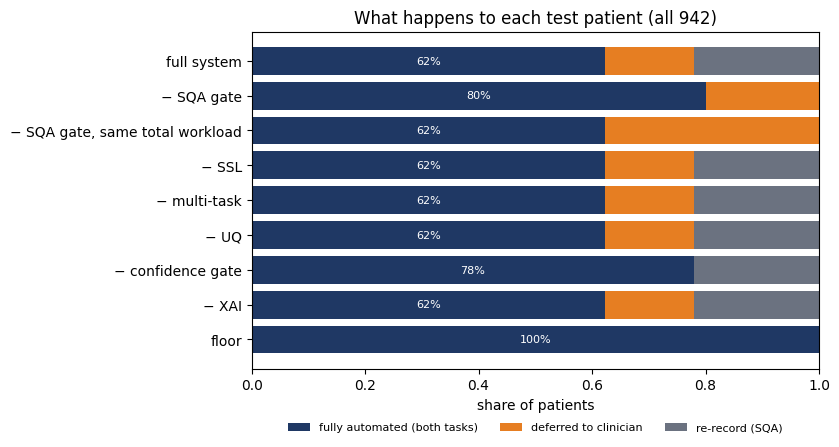

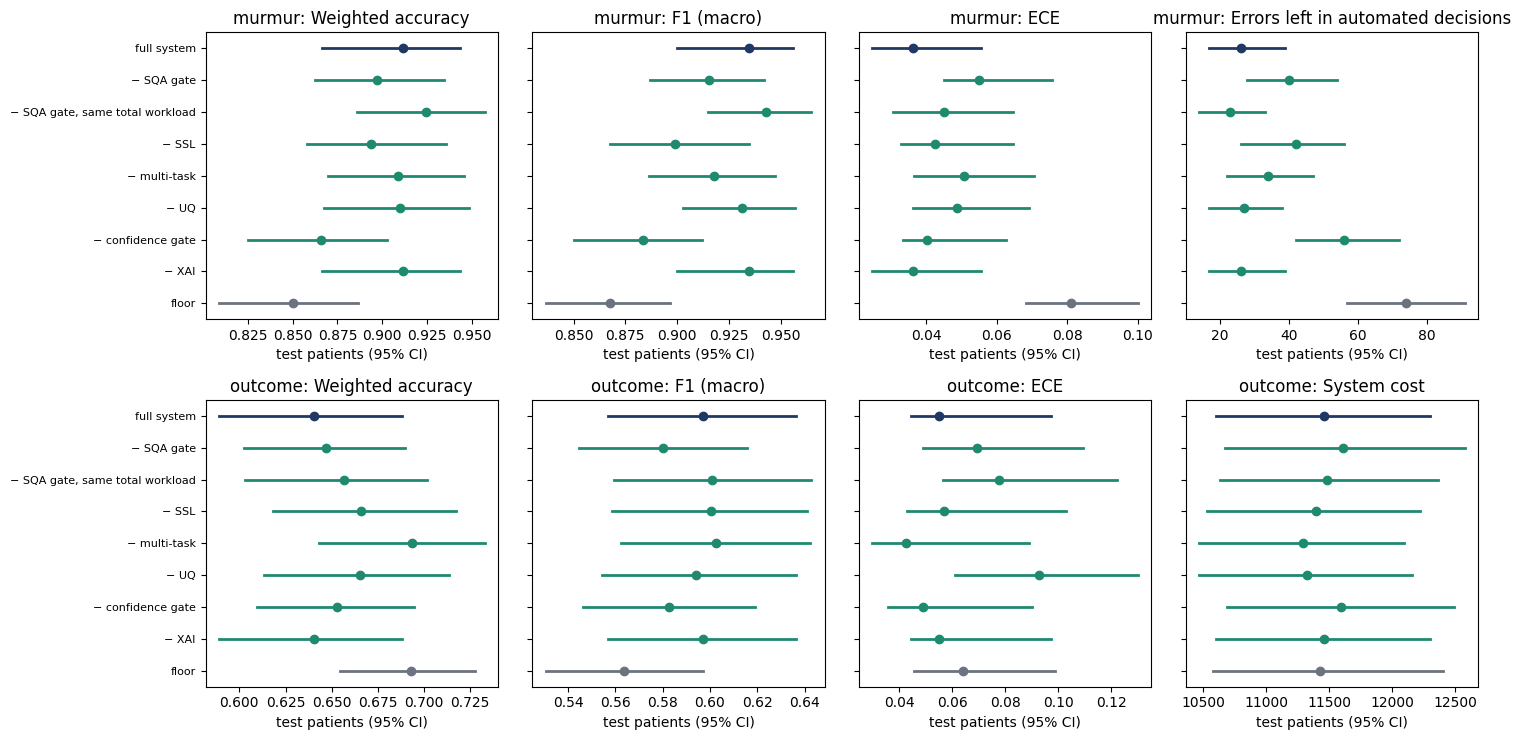

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y_ = np.arange(len(ROW_NAMES))
au = workload["share fully automated"].values; cl = workload["share deferred to clinician"].values; rr = workload["share re-recorded"].values
ax.barh(y_, au, color=NAVY, label="fully automated (both tasks)")
ax.barh(y_, cl, left=au, color=ORANGE, label="deferred to clinician")
ax.barh(y_, rr, left=au + cl, color=GRAY, label="re-record (SQA)")
for i, v in enumerate(au):
    ax.text(v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8)
ax.set_yticks(y_); ax.set_yticklabels(ROW_NAMES); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set(title="What happens to each test patient (all 942)", xlabel="share of patients")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq6_workload.png", dpi=200); plt.show()

PLOT = {"murmur": ["Weighted accuracy", "F1 (macro)", "ECE", "Errors left in automated decisions"],
        "outcome": ["Weighted accuracy", "F1 (macro)", "ECE", "System cost"]}
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for i, task in enumerate(TASKS):
    for j, metric in enumerate(PLOT[task]):
        ax = axes[i, j]
        for k, name in enumerate(ROW_NAMES):
            r = results[(results.task == task) & (results.row == name) & (results.metric == metric)].iloc[0]
            if not np.isfinite(r.value):
                continue
            c = NAVY if name == "full system" else (GRAY if name == "floor" else TEAL)
            ax.plot([r.ci_low, r.ci_high], [k, k], color=c, lw=2); ax.plot(r.value, k, "o", color=c, ms=6)
        ax.set_yticks(range(len(ROW_NAMES))); ax.set_yticklabels(ROW_NAMES if j == 0 else [""] * len(ROW_NAMES), fontsize=8)
        ax.set_ylim(len(ROW_NAMES) - 0.5, -0.5)
        ax.set(title=f"{task}: {metric}", xlabel="test patients (95% CI)")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq6_metrics.png", dpi=200); plt.show()

## 8. The answer rule, applied

*Components: ①–⑤ → RQ6's answer.*

**Rule metrics** (the methods document's system-level metrics that can be compared across systems at the same workload): weighted accuracy, F1 (macro) and ECE of the automated decisions, and system cost (outcome). "Correctly deferred" is reported but not used: a system that makes more errors has more errors to defer, so a component cannot be credited for deferring errors it created.

| verdict per component and task | condition (paired 95 % CIs, row minus full system) |
|---|---|
| **contributes** | removing it makes at least one rule metric worse and none better |
| **harmful** | removing it makes at least one rule metric better and none worse |
| **mixed** | some worse, some better |
| **no measurable contribution** | none worse, none better |

Components: ① SQA gate (− SQA gate row; the same-total-workload row is reported alongside, as stated in the RQ1 report), ② SSL, ③ multi-task, ④ UQ, the confidence gate. ⑤ XAI does not change decisions, so its row equals the full system by construction; its contribution is the explanation of each automated decision, whose quality RQ5 evaluated.

**Hypothesis** ("trustworthy screening emerges from the interaction … not from any single component alone"):
- **supported** if the full system beats the floor in both tasks (floor − full: at least one rule metric worse, none better) **and** each of ①–④ and the confidence gate contributes in at least one task;
- **partly supported** if the full system beats the floor in at least one task but the first condition is not met;
- **not supported** if it beats the floor in neither task.

In [9]:
RULE = {"murmur": ["Weighted accuracy", "F1 (macro)", "ECE"],
        "outcome": ["Weighted accuracy", "F1 (macro)", "ECE", "System cost"]}

def verdict_for(name, task):
    d = diffs[(diffs.task == task) & (diffs.row == name) & diffs.metric.isin(RULE[task])]
    w, b = (d.verdict == "worse").sum(), (d.verdict == "better").sum()
    v = "contributes" if w and not b else "harmful" if b and not w else "mixed" if w and b else "no measurable contribution"
    return v, ", ".join(d[d.verdict == "worse"].metric), ", ".join(d[d.verdict == "better"].metric)

COMPONENT_ROW = {"① SQA gate": "− SQA gate", "① SQA gate (same total workload, RQ1)": "− SQA gate, same total workload",
                 "② SSL": "− SSL", "③ multi-task": "− multi-task", "④ UQ": "− UQ", "confidence gate": "− confidence gate"}
ans = []
for comp, name in COMPONENT_ROW.items():
    for task in TASKS:
        v, w, b = verdict_for(name, task)
        ans.append({"component": comp, "task": task, "verdict": v, "worse without it": w, "better without it": b})
for task in TASKS:
    ans.append({"component": "⑤ XAI", "task": task, "verdict": "decisions unchanged by design (explanations: RQ5)",
                "worse without it": "", "better without it": ""})
answer = pd.DataFrame(ans)
display(answer)

beats_floor = {}
for task in TASKS:
    v, w, b = verdict_for("floor", task)
    beats_floor[task] = (v == "contributes")       # floor worse than the full system on ≥ 1 rule metric, better on none
    print(f"{task}: floor − full system → floor worse on [{w}], better on [{b}] → full system beats the floor: {beats_floor[task]}")
core = ["① SQA gate", "② SSL", "③ multi-task", "④ UQ", "confidence gate"]
each_contributes = all((answer[(answer.component == c) & (answer.verdict == "contributes")].shape[0] > 0) for c in core)
if all(beats_floor.values()) and each_contributes:
    hyp = "supported"
elif any(beats_floor.values()):
    hyp = "partly supported"
else:
    hyp = "not supported"
print(f"\nEach of ①–④ and the confidence gate contributes in at least one task: {each_contributes}")
print(f"Hypothesis: {hyp}")

,component,task,verdict,worse without it,better without it
0,① SQA gate,murmur,contributes,ECE,
1,① SQA gate,outcome,no measurable contribution,,
2,"① SQA gate (same total workload, RQ1)",murmur,no measurable contribution,,
3,"① SQA gate (same total workload, RQ1)",outcome,no measurable contribution,,
4,② SSL,murmur,contributes,F1 (macro),
5,② SSL,outcome,no measurable contribution,,
6,③ multi-task,murmur,no measurable contribution,,
7,③ multi-task,outcome,harmful,,Weighted accuracy
8,④ UQ,murmur,no measurable contribution,,
9,④ UQ,outcome,no measurable contribution,,


murmur: floor − full system → floor worse on [Weighted accuracy, F1 (macro), ECE], better on [] → full system beats the floor: True
outcome: floor − full system → floor worse on [], better on [Weighted accuracy] → full system beats the floor: False

Each of ①–④ and the confidence gate contributes in at least one task: False
Hypothesis: partly supported


In [10]:
# 8b. Unknown-murmur patients (clinicians could not call the murmur): how does each configuration handle them?
LABS = ["Unknown", "Present", "Absent"]
MUR = PAT.murmur.values
HANDLED = ["re-record", "clinician", "automated", "automated, called Present"]

def label_shares(name, ix, dfr):
    cov, lab = COV[name][ix], MUR[ix]
    yh = PRED[(name, "murmur")]["yhat"][ix]
    out = {}
    for L in LABS:
        m = lab == L
        if not m.any():
            continue
        auto = cov[m] & ~dfr[m]
        out[f"{L}|re-record"] = np.mean(~cov[m])
        out[f"{L}|clinician"] = np.mean(dfr[m])
        out[f"{L}|automated"] = np.mean(auto)
        out[f"{L}|automated, called Present"] = np.mean(auto & (yh[m] == 1))
    return out

pt_u = {name: label_shares(name, FULL_IX, DEF0[name]) for name in ROW_NAMES}
bs_u = {name: [] for name in ROW_NAMES}
for ix in tqdm(BIS, desc="Unknown-murmur bootstrap (gate re-ranked in every resample)"):
    dd = all_deferrals(ix)
    for name in ROW_NAMES:
        bs_u[name].append(label_shares(name, ix, dd[name]))

rows_u = []
for name in ROW_NAMES:
    B = pd.DataFrame(bs_u[name])
    for L in LABS:
        n = int((MUR == L).sum())
        for what in HANDLED:
            v = pt_u[name][f"{L}|{what}"]
            b = B[f"{L}|{what}"].values.astype(float)
            lo, hi = np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)
            rows_u.append({"row": name, "murmur label": L, "patients": n, "handled as": what, "share": v,
                           "count": int(round(v * n)), "ci_low": lo, "ci_high": hi,
                           "cell": f"{v:.1%} ({int(round(v * n))}) [{lo:.1%}, {hi:.1%}]"})
unknown_tab = pd.DataFrame(rows_u)
display(unknown_tab.pivot_table(index=["row", "murmur label"], columns="handled as", values="cell",
                                aggfunc="first", sort=False)[HANDLED])

u_full = unknown_tab[(unknown_tab.row == "full system") & (unknown_tab["murmur label"] == "Unknown")].set_index("handled as")
print(f"Full system: {u_full.loc['re-record', 'count'] + u_full.loc['clinician', 'count']} of {int((MUR == 'Unknown').sum())} "
      f"Unknown-murmur patients are not decided automatically "
      f"({1 - u_full.loc['automated', 'share']:.1%}); {u_full.loc['automated, called Present', 'count']} of the automated ones are called Present")
unknown_tab.to_csv(OUT / "rq6_unknown.csv", index=False)

Unknown-murmur bootstrap (gate re-ranked in every resample):   0%|          | 0/1000 [00:00<?, ?it/s]

handled as                                                     re-record                   clinician                      automated   automated, called Present
row                             murmur label                                                                                                                   
full system                     Unknown        82.4% (56) [72.7%, 90.9%]      8.8% (6) [1.9%, 14.9%]         8.8% (6) [2.9%, 17.2%]       1.5% (1) [0.0%, 5.4%]
                                Present         13.4% (24) [8.2%, 18.7%]    12.8% (23) [8.4%, 17.4%]     73.7% (132) [67.4%, 80.3%]  63.7% (114) [55.7%, 70.7%]
                                Absent        18.4% (128) [15.6%, 21.6%]  17.0% (118) [15.7%, 18.5%]     64.6% (449) [61.7%, 67.0%]       1.2% (8) [0.4%, 2.2%]
− SQA gate                      Unknown            0.0% (0) [0.0%, 0.0%]   33.8% (23) [21.5%, 43.1%]      66.2% (45) [56.9%, 78.5%]      7.4% (5) [1.7%, 16.7%]
                                Present            0.0% (0) [0.0%, 0.0%]    14.0% (25) [9.7%, 19.0%]     86.0% (154) [81.0%, 90.3%]  72.6% (130) [66.3%, 79.2%]
                                Absent             0.0% (0) [0.0%, 0.0%]  20.1% (140) [18.8%, 22.0%]     79.9% (555) [78.0%, 81.2%]      2.3% (16) [1.3%, 3.6%]
− SQA gate, same total workload Unknown            0.0% (0) [0.0%, 0.0%]   47.1% (32) [34.0%, 58.1%]      52.9% (36) [41.9%, 66.0%]      7.4% (5) [1.5%, 14.3%]
                                Present            0.0% (0) [0.0%, 0.0%]   23.5% (42) [17.7%, 29.7%]     76.5% (137) [70.3%, 82.3%]  68.2% (122) [61.0%, 74.3%]
                                Absent             0.0% (0) [0.0%, 0.0%]  40.4% (281) [37.4%, 43.7%]     59.6% (414) [56.3%, 62.6%]       1.2% (8) [0.4%, 2.0%]
− SSL                           Unknown        82.4% (56) [72.7%, 90.9%]       2.9% (2) [0.0%, 7.7%]       14.7% (10) [6.2%, 23.8%]       4.4% (3) [0.0%, 9.7%]
                                Present         13.4% (24) [8.2%, 18.7%]    11.7% (21) [7.9%, 16.5%]     74.9% (134) [68.4%, 81.0%]  64.2% (115) [57.1%, 71.1%]
                                Absent        18.4% (128) [15.6%, 21.6%]  17.8% (124) [16.5%, 19.1%]     63.7% (443) [61.0%, 66.5%]      3.3% (23) [1.8%, 4.8%]
− multi-task                    Unknown        82.4% (56) [72.7%, 90.9%]       2.9% (2) [0.0%, 7.5%]       14.7% (10) [6.2%, 23.5%]       4.4% (3) [0.0%, 9.9%]
                                Present         13.4% (24) [8.2%, 18.7%]    11.2% (20) [7.8%, 15.9%]     75.4% (135) [68.6%, 81.2%]  65.9% (118) [58.5%, 72.7%]
                                Absent        18.4% (128) [15.6%, 21.6%]  18.0% (125) [16.5%, 19.1%]     63.6% (442) [61.0%, 66.2%]      2.4% (17) [1.3%, 3.8%]
− UQ                            Unknown        82.4% (56) [72.7%, 90.9%]      5.9% (4) [1.4%, 12.2%]        11.8% (8) [3.6%, 19.7%]       1.5% (1) [0.0%, 5.0%]
                                Present         13.4% (24) [8.2%, 18.7%]    14.0% (25) [9.3%, 18.4%]     72.6% (130) [66.5%, 79.1%]  62.6% (112) [55.3%, 70.2%]
                                Absent        18.4% (128) [15.6%, 21.6%]  17.0% (118) [15.6%, 18.3%]     64.6% (449) [61.8%, 67.2%]       1.3% (9) [0.6%, 2.2%]
− confidence gate               Unknown        82.4% (56) [72.7%, 90.9%]       0.0% (0) [0.0%, 0.0%]       17.6% (12) [9.1%, 27.3%]      5.9% (4) [1.4%, 11.6%]
                                Present         13.4% (24) [8.2%, 18.7%]       0.0% (0) [0.0%, 0.0%]     86.6% (155) [81.3%, 91.8%]  69.3% (124) [62.1%, 76.5%]
                                Absent        18.4% (128) [15.6%, 21.6%]       0.0% (0) [0.0%, 0.0%]     81.6% (567) [78.4%, 84.4%]      3.6% (25) [2.3%, 5.1%]
− XAI                           Unknown        82.4% (56) [72.7%, 90.9%]      8.8% (6) [1.9%, 14.9%]         8.8% (6) [2.9%, 17.2%]       1.5% (1) [0.0%, 5.4%]
                                Present         13.4% (24) [8.2%, 18.7%]    12.8% (23) [8.4%, 17.4%]     73.7% (132) [67.4%, 80.3%]  63.7% (114) [55.7%, 70.7%]


Full system: 62 of 68 Unknown-murmur patients are not decided automatically (91.2%); 1 of the automated ones are called Present


## 9. Save

| file | contents | used by |
|---|---|---|
| `rq6_patient_decisions.csv` | per row × task × patient: probability, threshold, Chow risk, covered by SQA, deferred, decision, automated | report, RQ7 |
| `rq6_workload.csv` | patient workload per row: re-recorded, deferred to a clinician, fully automated | report |
| `rq6_results.csv` | every metric per row × task with 95 % CI | report |
| `rq6_differences.csv` | row − full system, paired 95 % CI and verdict | report |
| `rq6_answer.csv` | component verdicts and the hypothesis | report |
| `rq6_temperatures.csv` | recomputed temperatures (equal to RQ3's) | report |

Literature ceilings (CardioPHON, Xu et al.) are taken from the papers' own reported numbers in the report; nothing is recomputed for them here.

In [11]:
dec_out = []
for name in ROW_NAMES:
    for task in TASKS:
        P = PRED[(name, task)]
        df = PAT[["patient_id", "group", "fold", "murmur", "outcome"]].copy()
        df.insert(0, "task", task); df.insert(0, "row", name)
        df["y"] = PLABEL[task]
        df["p"], df["t"], df["risk"], df["yhat"] = P["p"], P["t"], P["risk"], P["yhat"]
        df["covered"], df["deferred"] = COV[name], DEF0[name]
        df["auto"] = COV[name] & ~DEF0[name]
        dec_out.append(df)
pd.concat(dec_out).to_csv(OUT / "rq6_patient_decisions.csv", index=False)
workload.to_csv(OUT / "rq6_workload.csv", index=False)
results.to_csv(OUT / "rq6_results.csv", index=False)
diffs.to_csv(OUT / "rq6_differences.csv", index=False)
answer.assign(hypothesis=hyp).to_csv(OUT / "rq6_answer.csv", index=False)
temps.to_csv(OUT / "rq6_temperatures.csv", index=False)
for p_ in sorted(OUT.rglob("*")):
    if p_.is_file():
        print(f"  {p_.relative_to(OUT)}  ({p_.stat().st_size / 1e6:.2f} MB)")

  figures/rq6_metrics.png  (0.16 MB)
  figures/rq6_workload.png  (0.09 MB)
  rq6_answer.csv  (0.00 MB)
  rq6_differences.csv  (0.03 MB)
  rq6_patient_decisions.csv  (1.91 MB)
  rq6_results.csv  (0.03 MB)
  rq6_temperatures.csv  (0.00 MB)
  rq6_unknown.csv  (0.01 MB)
  rq6_workload.csv  (0.00 MB)
